# Лабораторная работа № 1. Регрессионный анализ

**Цель:** научиться применять модели линейной регрессии библиотеки `scikit-learn` к эмпирическим данным.

**Результат:** построить эмпирическую формулу зависимости второй колонки данных от первой.

В CSV-файле предполагаются два числовых столбца без заголовков: первый — признак `x`, второй — целевая переменная `y`. Если в файле есть заголовки, в ячейке загрузки нужно изменить параметр `header=None` на `header=0`.


## 1. Импорт библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

%matplotlib inline

## 2. Загрузка данных

In [3]:
file_path = "dataset/lab1-05.csv"

data = pd.read_csv(file_path, header=None)

data.columns = ["x", "y"]

data["x"] = pd.to_numeric(data["x"], errors="coerce")
data["y"] = pd.to_numeric(data["y"], errors="coerce")
data = data.dropna()

print("Количество наблюдений:", len(data))
display(data.head())
print(data.describe())

Количество наблюдений: 200


,x,y
0,8.313131,1.958272
1,4.878788,0.690539
2,2.898990,5.182053
3,7.303030,-0.801916
4,8.757576,2.016715


                x           y
count  200.000000  200.000000
mean     5.000000    3.198134
std      2.321035    4.498626
min      1.000000   -2.586296
25%      3.010101    0.282800
50%      5.000000    1.449313
75%      6.989899    4.840191
max      9.000000   17.472711


## 3. Визуализация исходных данных

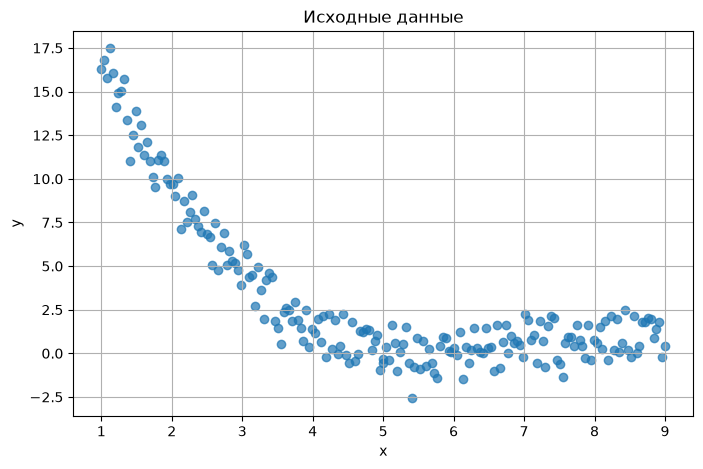

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(data["x"], data["y"], alpha=0.7)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Исходные данные")
plt.grid(True)
plt.show()

## 4. Разделение на обучающую и тестовую выборки

80% данных используем для обучения модели, 20% — для проверки качества. `random_state=42` позволяет получить воспроизводимое разбиение.

In [5]:
X = data[["x"]]
y = data["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))

Обучающая выборка: 160
Тестовая выборка: 40


## 5. Обучение линейной регрессии

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

a = model.coef_[0]
b = model.intercept_

print(f"Коэффициент a = {a:.6f}")
print(f"Свободный член b = {b:.6f}")
print(f"Эмпирическая формула: y = {a:.6f} * x + ({b:.6f})")

Коэффициент a = -1.452062
Свободный член b = 10.338178
Эмпирическая формула: y = -1.452062 * x + (10.338178)


## 6. Оценка качества модели на тестовой выборке

In [7]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  = {mse:.6f}")
print(f"RMSE = {rmse:.6f}")
print(f"MAE  = {mae:.6f}")
print(f"R²   = {r2:.6f}")

MSE  = 8.569835
RMSE = 2.927428
MAE  = 2.332567
R²   = 0.633356


**Интерпретация метрик:**
- `MAE` — средняя абсолютная ошибка прогноза.
- `RMSE` — корень из средней квадратичной ошибки; сильнее реагирует на большие ошибки.
- `R²` — коэффициент детерминации. Значение ближе к 1 обычно означает, что модель лучше описывает данные; отрицательное значение означает, что на тестовой выборке модель хуже предсказания средним значением `y`.

## 7. Визуализация результата

На графике показаны все исходные наблюдения и прямая, построенная обученной моделью.

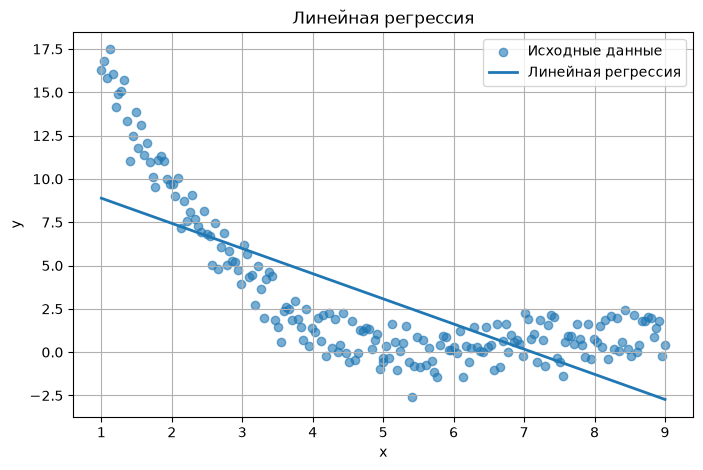

In [8]:
x_line = np.linspace(data["x"].min(), data["x"].max(), 200)
y_line = model.predict(pd.DataFrame({"x": x_line}))

plt.figure(figsize=(8, 5))
plt.scatter(data["x"], data["y"], alpha=0.6, label="Исходные данные")
plt.plot(x_line, y_line, linewidth=2, label="Линейная регрессия")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Линейная регрессия")
plt.legend()
plt.grid(True)
plt.show()

## 8. Вывод

В ходе работы данные были загружены из CSV-файла, визуализированы и разделены на обучающую и тестовую выборки. На обучающей выборке построена модель `LinearRegression` из `scikit-learn`, а её качество оценено на тестовой выборке.

Полученная эмпирическая формула имеет вид:

\[
y = ax + b
\],

где `a` и `b` — коэффициенты, рассчитанные моделью и выведенные в разделе 5. Метрики из раздела 6 позволяют оценить качество аппроксимации.

**Примечание:** линейная регрессия подходит, если зависимость приблизительно линейная. Если график исходных данных показывает выраженную нелинейность, одной прямой может быть недостаточно.